#### The inverse travelling wave
 HSG
 20.09

In [15]:
import numpy as np 
import matplotlib.pyplot as plt 
from spectralNewton import solve_with_continuation

In [21]:
# Let us create a travelling wave:
P = 2*np.pi
N = 2**8

amp_target = 0.05
mean = 0.0

u, mk, mask = solve_with_continuation(P=P, amp_target=amp_target, N=N, mean=mean)

phi_hat = u[:-2]
c_sol, B_sol = u[-2], u[-1]

x = np.linspace(0,P,N, endpoint=False)
dx = P/N
#rfft wave numbers
k = 2*np.pi*np.fft.rfftfreq(N,dx)

In [10]:
def nonlinear_hat(phi_hat,mask,N):
    phi = np.fft.irfft(phi_hat*mask,n=N)
    nl = 0.5*phi**2
    return np.fft.rfft(nl)

In [14]:
nl_hat = nonlinear_hat(phi_hat,mask,N)

mk_lsm = c_sol - nl_hat[1:]/phi_hat[1:]

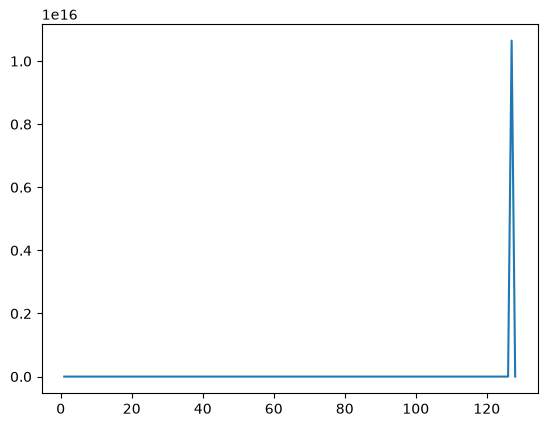

In [25]:
plt.plot(k[1:], mk[1:] - mk_lsm.real)

In [44]:
plot_mask = np.abs(mk[1:] - mk_lsm.real) < 1e3

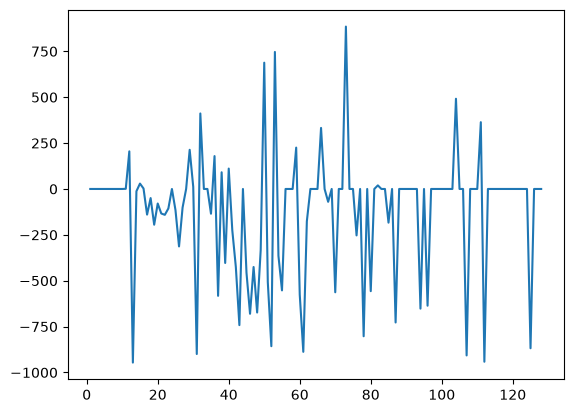

In [46]:
k_p = k[1:]*plot_mask
diff_plot = (mk[1:] - mk_lsm.real)*plot_mask
plt.plot(k[1:], diff_plot)
plt.show()

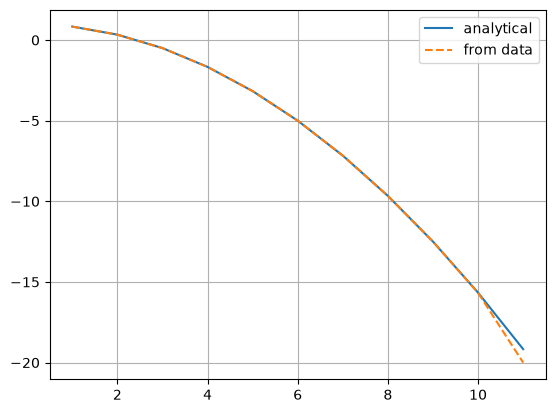

In [62]:
idx = 12
plt.plot(k[1:idx], mk[1:idx] , label = "analytical")
plt.plot(k[1:idx], mk_lsm.real[:idx-1], '--' , label = "from data")
plt.legend()
plt.grid()
plt.show()

Kan se ut som om det kun er gyldig for $j < 10$

In [67]:
# LSM on the "valid area" 
idx = 11
k_lsm = k[1:idx]
mk_lsm = mk_lsm[:idx-1]
A = np.column_stack([np.ones_like(k_lsm), k_lsm , k_lsm**2, k_lsm**3])
x,residual, rank , s = np.linalg.lstsq(A,mk_lsm.real, rcond=None)

print(x)

[ 1.00394465e+00 -4.19520332e-03 -1.65563271e-01 -8.04564110e-05]
